# TrustXRay — 04. Explainability with Grad-CAM

**Questions left open by notebooks 01–03:**
1. Does the model look at the **lungs**, or at **shortcuts** such as the laterality marker ("R") or the image borders? (risk found in notebook 01)
2. Why does it make **confident errors** — normal X-rays predicted as pneumonia with 30/30 votes? (found in notebook 03)

**Grad-CAM** (Selvaraju et al., 2017) produces a heatmap showing which regions of the image most influenced the decision. Red = strong influence.

> Runs on GPU or CPU. Needs `resnet18_baseline.pt` and `trustxray_config.json` in `MyDrive/TrustXRay` (from notebooks 02 and 03).

In [1]:
!pip install -q medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 7.1 MB/s eta 0:00:00


In [2]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms, models
from medmnist import PneumoniaMNIST

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
SIZE, DATA_DIR, FIG_DIR = 224, "./data", "./figures"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/TrustXRay"
except ImportError:
    SAVE_DIR = "./models"
MODEL_PATH = os.path.join(SAVE_DIR, "resnet18_baseline.pt")
CONFIG_PATH = os.path.join(SAVE_DIR, "trustxray_config.json")
assert os.path.exists(MODEL_PATH), "Run notebook 02 first"
assert os.path.exists(CONFIG_PATH), "Run notebook 03 first"
config = json.load(open(CONFIG_PATH))
THR_LOGIT = config["threshold_logit"]
print("Decision threshold (logit):", round(THR_LOGIT, 3))

Device: cuda
Mounted at /content/drive
Decision threshold (logit): -3.087


In [3]:
def build_model(dropout=0.3):
    model = models.resnet18(weights=None)
    model.fc = nn.Sequential(nn.Dropout(p=dropout), nn.Linear(model.fc.in_features, 1))
    return model

model = build_model().to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()   # dropout OFF: Grad-CAM explains the standard (deterministic) prediction

IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
test_ds = PneumoniaMNIST(split="test", transform=eval_tf, download=True, size=SIZE, as_rgb=True, root=DATA_DIR)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2)
raw_imgs = test_ds.imgs                # original grayscale images, for display
labels = test_ds.labels.ravel()

with torch.no_grad():
    logits = torch.cat([model(x.to(DEVICE)).cpu() for x, _ in test_loader]).numpy().ravel()
preds = (logits >= THR_LOGIT).astype(int)
correct = preds == labels
print(f"test={len(labels)}  errors={(~correct).sum()}  (FP={((preds == 1) & (labels == 0)).sum()}, FN={((preds == 0) & (labels == 1)).sum()})")

100%|██████████| 214M/214M [11:51<00:00, 301kB/s]


test=624  errors=32  (FP=29, FN=3)


## 1. How Grad-CAM works

1. We look at the **last convolutional block** of ResNet18 (`layer4`): 512 feature maps of size 7×7, each detecting a visual pattern.
2. We compute the **gradient** of the pneumonia score with respect to each feature map → how much each map matters for the decision.
3. We sum the maps weighted by their importance, keep only the positive part (ReLU), and upscale the 7×7 result to 224×224.

Result: a heatmap of the regions that **pushed the model toward "pneumonia"**.

In [4]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save_activation)

    def _save_activation(self, module, inp, out):
        self.activations = out
        out.register_hook(self._save_gradient)

    def _save_gradient(self, grad):
        self.gradients = grad

    def __call__(self, x):
        self.model.zero_grad()
        score = self.model(x).squeeze()            # pneumonia logit
        score.backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)          # [1, 512, 1, 1]
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze().detach().cpu().numpy()
        return cam / (cam.max() + 1e-8), score.item()

gradcam = GradCAM(model, model.layer4)

def explain(i):
    x = test_ds[i][0].unsqueeze(0).to(DEVICE).requires_grad_(True)
    return gradcam(x)

## 2. Visualize: correct and wrong predictions

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


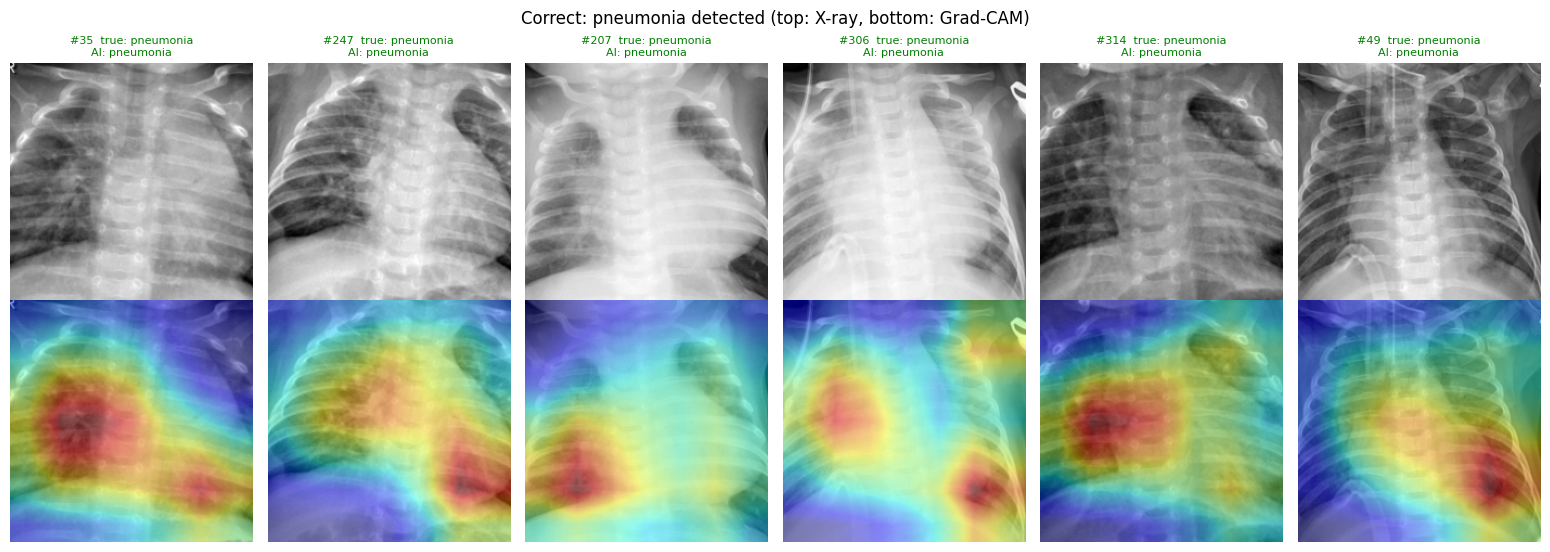

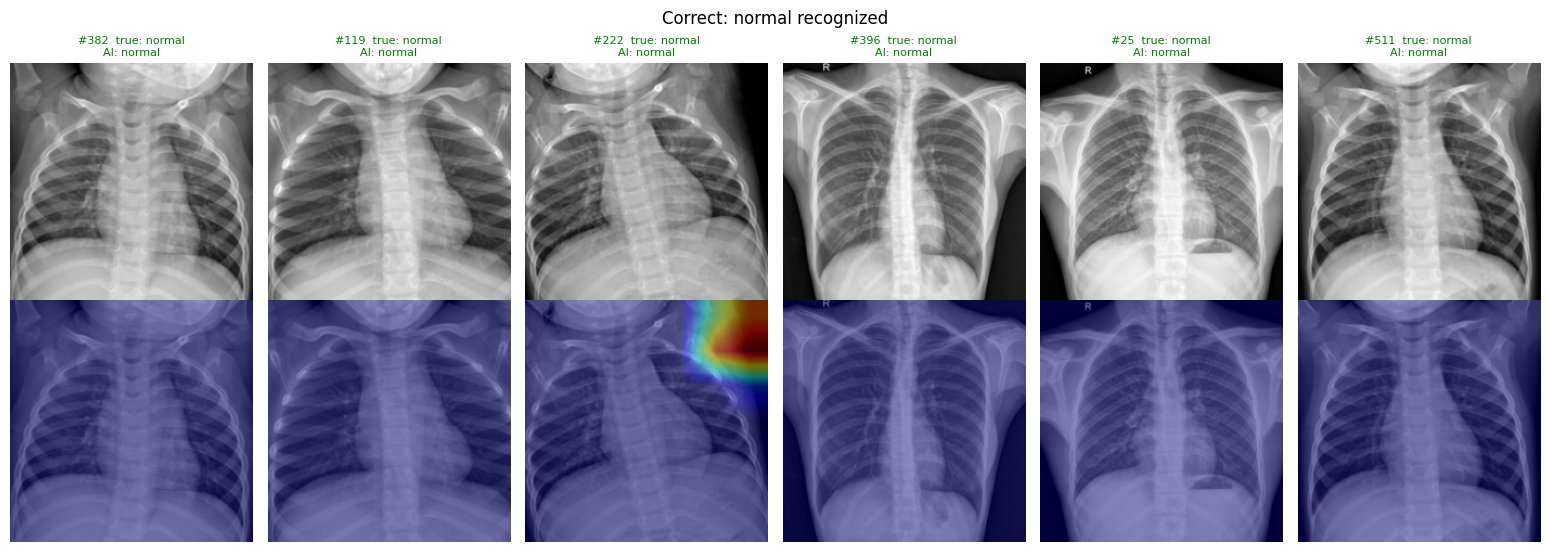

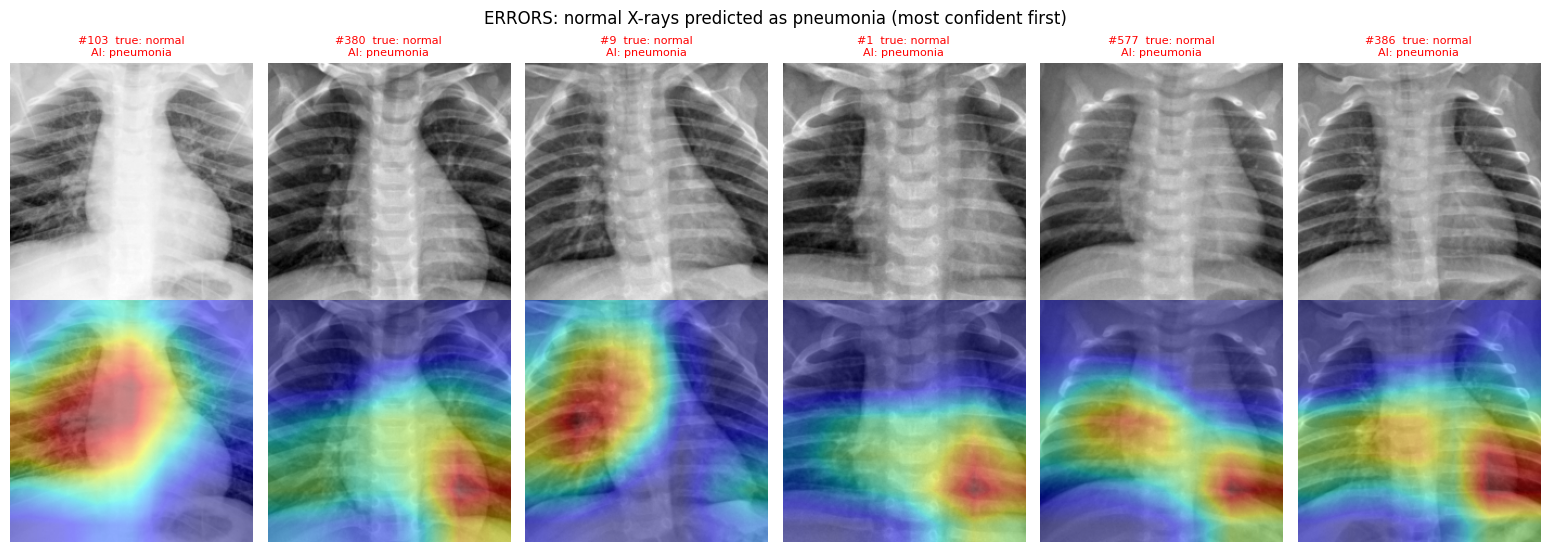

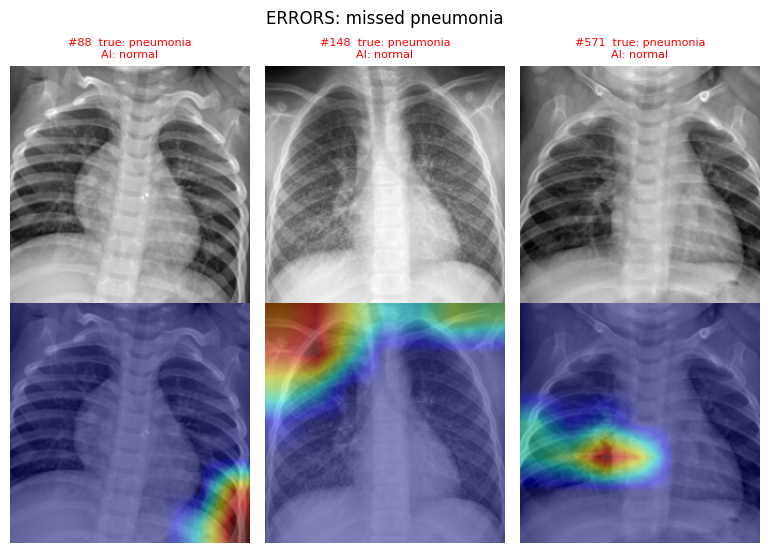

In [5]:
def show_cams(indices, title, path, n=6):
    indices = list(indices)[:n]
    if not indices:
        print(f"(no images for: {title})"); return
    fig, axes = plt.subplots(2, len(indices), figsize=(2.6 * len(indices), 5.6))
    axes = np.array(axes).reshape(2, -1)
    for col, i in enumerate(indices):
        cam, _ = explain(i)
        true = "pneumonia" if labels[i] == 1 else "normal"
        pred = "pneumonia" if preds[i] == 1 else "normal"
        axes[0, col].imshow(raw_imgs[i], cmap="gray")
        axes[0, col].set_title(f"#{i}  true: {true}\nAI: {pred}", fontsize=8,
                               color="green" if correct[i] else "red")
        axes[1, col].imshow(raw_imgs[i], cmap="gray")
        axes[1, col].imshow(cam, cmap="jet", alpha=0.45)
        for ax in axes[:, col]: ax.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

tp = np.where((preds == 1) & (labels == 1))[0]
tn = np.where((preds == 0) & (labels == 0))[0]
fp = np.where((preds == 1) & (labels == 0))[0]
fn = np.where((preds == 0) & (labels == 1))[0]

# most confident cases first (largest distance to the threshold)
by_conf = lambda idx: idx[np.argsort(-np.abs(logits[idx] - THR_LOGIT))]
show_cams(by_conf(tp), "Correct: pneumonia detected (top: X-ray, bottom: Grad-CAM)", f"{FIG_DIR}/gradcam_true_positive.png")
show_cams(by_conf(tn), "Correct: normal recognized", f"{FIG_DIR}/gradcam_true_negative.png")
show_cams(by_conf(fp), "ERRORS: normal X-rays predicted as pneumonia (most confident first)", f"{FIG_DIR}/gradcam_false_positive.png")
show_cams(fn, "ERRORS: missed pneumonia", f"{FIG_DIR}/gradcam_false_negative.png")

## 3. Shortcut check: does the model look at the borders?

We have no lung masks in this dataset, so we use a simple, transparent check:
- **Border zone** = the outer 12% of the image (where text markers like "R", labels and collimation edges usually are).
- For each X-ray we compute the **share of the Grad-CAM heat located in the border zone**.

If the model relied on markers or borders, this share would be high. This is a rough heuristic, not a lung segmentation — we also check the flagged images by eye.

Border zone = 41% of the image area
Mean share of heat in the border zone: 33.6%  (a uniform heatmap would give 41%)
  correct predictions: 33.6%
  errors:              32.5%
  false positives:     30.1%
X-rays with > 60% of the heat in the border: 92 / 624


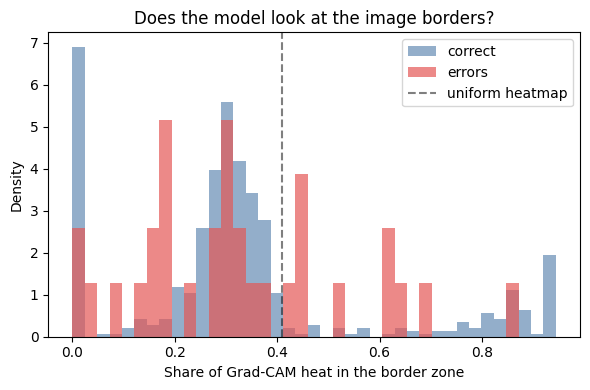

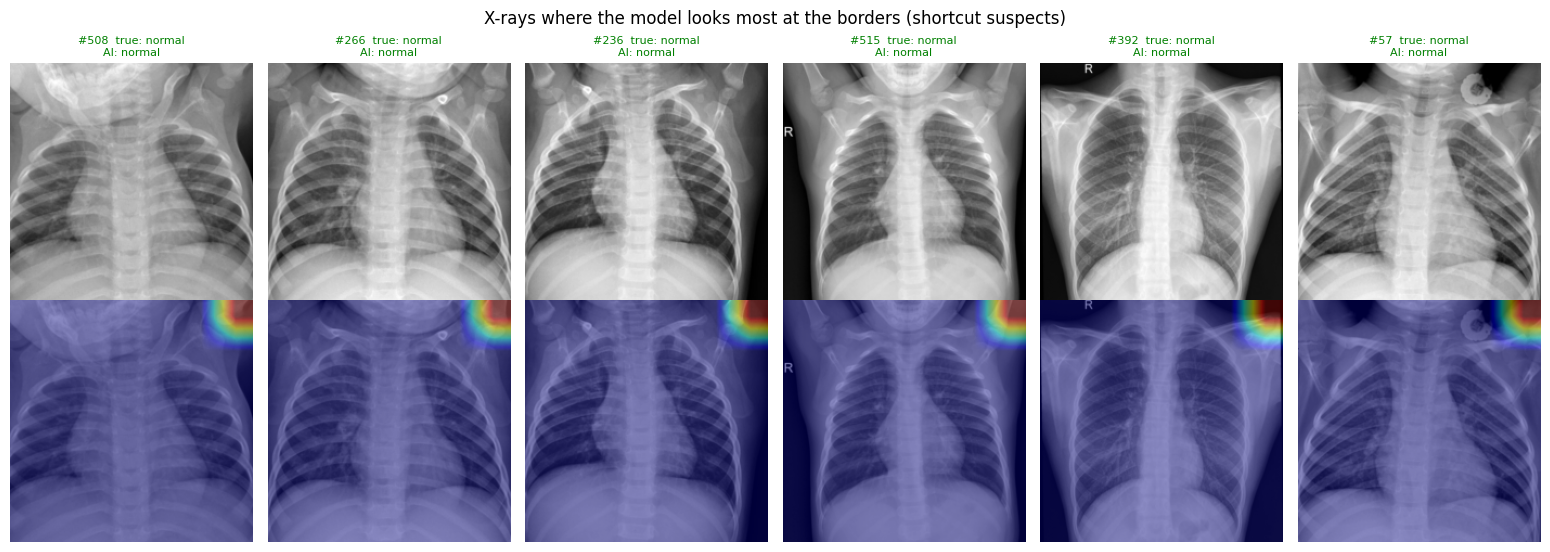

In [6]:
MARGIN = int(0.12 * SIZE)
border_mask = np.ones((SIZE, SIZE), bool)
border_mask[MARGIN:-MARGIN, MARGIN:-MARGIN] = False
print(f"Border zone = {100 * border_mask.mean():.0f}% of the image area")

border_share = np.zeros(len(labels))
for i in range(len(labels)):
    cam, _ = explain(i)
    border_share[i] = cam[border_mask].sum() / (cam.sum() + 1e-8)

print(f"Mean share of heat in the border zone: {100 * border_share.mean():.1f}%  "
      f"(a uniform heatmap would give {100 * border_mask.mean():.0f}%)")
print(f"  correct predictions: {100 * border_share[correct].mean():.1f}%")
print(f"  errors:              {100 * border_share[~correct].mean():.1f}%")
print(f"  false positives:     {100 * border_share[fp].mean():.1f}%" if len(fp) else "")
print(f"X-rays with > 60% of the heat in the border: {(border_share > 0.60).sum()} / {len(labels)}")

plt.figure(figsize=(6, 4))
bins = np.linspace(0, max(0.6, border_share.max()), 40)
plt.hist(border_share[correct], bins=bins, alpha=0.6, density=True, label="correct", color="#4C78A8")
plt.hist(border_share[~correct], bins=bins, alpha=0.7, density=True, label="errors", color="#E45756")
plt.axvline(border_mask.mean(), color="k", ls="--", alpha=0.5, label="uniform heatmap")
plt.xlabel("Share of Grad-CAM heat in the border zone"); plt.ylabel("Density")
plt.title("Does the model look at the image borders?"); plt.legend(); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/gradcam_border_share.png", dpi=150); plt.show()

show_cams(np.argsort(-border_share), "X-rays where the model looks most at the borders (shortcut suspects)",
          f"{FIG_DIR}/gradcam_border_suspects.png")

In [7]:
pos = preds == 1
print(f"Predicted pneumonia (n={pos.sum()}): border share = {100 * border_share[pos].mean():.1f}%")
print(f"Predicted normal    (n={(~pos).sum()}): border share = {100 * border_share[~pos].mean():.1f}%")
print(f"Shortcut suspects (>60% border) among predicted pneumonia: {(border_share[pos] > 0.60).sum()} / {pos.sum()}")

Predicted pneumonia (n=416): border share = 30.2%
Predicted normal    (n=208): border share = 40.3%
Shortcut suspects (>60% border) among predicted pneumonia: 3 / 416


## 4. Observations

- **Correct pneumonia predictions:** the heat falls on the lung fields (often the lower zones, where opacities are) → the model uses relevant anatomical regions.
- **Correct normal predictions:** the heatmap is almost empty — expected, since Grad-CAM shows evidence *for* pneumonia.
- **Shortcut check:** for X-rays predicted as pneumonia (n=416), only 30.2% of the heat is in the border zone (uniform heatmap = 41%) and only 3 / 416 have more than 60% of their heat in the border → the model focuses on the lungs. For X-rays predicted as normal (n=208), the border share is 40.3% ≈ uniform: these heatmaps are nearly empty noise, which explains the "shortcut suspects" (a normalization artifact). No evidence that the model uses the "R" laterality marker.
- **Confident false positives:** the heat is inside the lungs / near the heart, on normal X-rays that look whiter, hazier or less contrasted → errors seem driven by image appearance (exposure, contrast) mimicking opacities, not by shortcuts (visual hypothesis).
- **Missed pneumonia:** weak, misplaced heatmaps; one case shows a diffuse pattern rather than a focal opacity.
- **Limitations:** Grad-CAM is coarse (7×7), shows correlation not causation, and no lung masks are available for a precise check.